# Clase 10 · Clustering, parte 1: segmentar clientes sin target

**Machine Learning** · Programa de Especialización Data Scientist · Sesión 10 de 14 · segunda hora

Docente: **Josef Renato Rodriguez**

---

## Cambiamos de pregunta

Hasta ahora siempre hubo un **target**: el precio de una casa, si el cliente acepta el depósito, si cae en default.
Hoy no hay. El área comercial del banco quiere responder otra cosa:

> **¿Qué tipos de clientes tenemos en la cartera de tarjetas, según cómo usan la tarjeta?**

No hay una columna «tipo de cliente» que predecir. Hay que **descubrir** los grupos: eso es el *clustering*, el ejemplo más
usado de aprendizaje **no supervisado**.

Usamos a los **6 685 clientes de la cartera de la Clase 9** que tienen foto en 2026, con su comportamiento promedio de enero a
junio de 2026: cuánto gastan, en qué, cuánto pagan, si sacan efectivo, si usan la app. Y al final cruzamos los segmentos con el
**default** de la Clase 9, porque un segmento solo sirve si dice algo del negocio.

## Qué vas a hacer en esta hora

| Bloque | Contenido | Min |
|---|---|---|
| A | Los datos, las distancias y por qué hay que **escalar** | 15 |
| B | **K-Means**: cómo funciona y cómo elegir *k* con el codo y la silueta | 20 |
| C | **Perfilar y nombrar** los segmentos, y cruzarlos con el default | 15 |

La **parte 2** (próxima clase): jerárquico, DBSCAN y HDBSCAN, mezclas gaussianas, y cómo comparar algoritmos.

---
## Celda 0 · Librerías y datos

La celda lee dos archivos directo del repositorio del curso ([Super_ML_course](https://github.com/josefrodrim/Super_ML_course)):

- `segmentacion_tarjetas.csv` (carpeta `Clase 10/Data`): **una fila por cliente**, 15 variables. Es la base de hoy.
- `cartera_tarjetas.csv` (carpeta `Clase_9/Datos`): la de la Clase 9. Solo la usamos al final, para el default.

Y deja listas `VARS`, las **12 variables de comportamiento** con las que vamos a agrupar, y `LOG`, las cuatro de ellas que
son conteos o montos muy sesgados. El diccionario de variables está en `Clase 10/Data/diccionario_segmentacion_tarjetas.md`.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings("ignore")

SEED = 42
NAVY, BLUE, MAG, GREEN, GRAY = "#0A2559", "#1A56E8", "#E6115E", "#12B886", "#5B6B87"
COLORES = [BLUE, MAG, GREEN, "#F59F00", "#7048E8", GRAY, NAVY, "#0CA678"]
plt.rcParams.update({
    "figure.figsize": (7, 4.2), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})

def check(nombre, obtenido, esperado, tol=1e-3):
    if obtenido is None:
        print(f"[ ] {nombre}: todavía no calculaste nada")
        return False
    ok = abs(float(obtenido) - float(esperado)) <= tol
    print(f"{'[OK]' if ok else '[X ]'} {nombre}")
    print(f"     tu resultado: {float(obtenido):.4f}   |   esperado: {float(esperado):.4f}")
    return ok

def check_bool(nombre, cond, pista=""):
    print(f"{'[OK]' if cond else '[X ]'} {nombre}")
    if not cond and pista:
        print(f"     pista: {pista}")
    return bool(cond)

URL_SEG = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase%2010/Data/segmentacion_tarjetas.csv"
URL_CARTERA = "https://raw.githubusercontent.com/josefrodrim/Super_ML_course/main/Clase_9/Datos/cartera_tarjetas.csv"

seg = pd.read_csv(URL_SEG)
cartera = pd.read_csv(URL_CARTERA)

ID = "id_cliente"
VARS = ["gasto_mensual_prom", "num_transacciones_mes", "ticket_promedio",
        "pct_supermercado", "pct_restaurantes", "pct_viajes", "pct_online",
        "utilizacion_prom", "pct_pago_saldo", "num_avances_6m", "pct_operaciones_app", "meses_sin_uso_6m"]
LOG = ["gasto_mensual_prom", "num_transacciones_mes", "ticket_promedio", "num_avances_6m"]   # montos y conteos sesgados
PERFIL = ["edad", "antiguedad_meses", "linea_credito"]                                        # para describir, no para agrupar

print(f"{len(seg):,} clientes · {seg.shape[1]} columnas".replace(",", " "))
seg.head()

6 685 clientes · 16 columnas


,id_cliente,edad,antiguedad_meses,linea_credito,gasto_mensual_prom,num_transacciones_mes,ticket_promedio,pct_supermercado,pct_restaurantes,pct_viajes,pct_online,utilizacion_prom,pct_pago_saldo,num_avances_6m,pct_operaciones_app,meses_sin_uso_6m
0,102992,23,42,7600,741,13,57.0,0.462,0.032,0.035,0.166,0.698,0.035,1,0.403,0
1,105839,23,74,6100,883,52,17.0,0.012,0.267,0.010,0.616,0.343,0.144,0,0.869,0
2,105969,53,101,4600,1124,17,66.1,0.586,0.096,0.019,0.198,0.363,0.677,0,0.459,0
3,107034,54,45,21400,1159,31,37.4,0.395,0.414,0.010,0.062,0.751,0.197,0,0.084,1
4,103700,40,109,5800,1337,17,78.7,0.362,0.235,0.046,0.095,0.334,0.712,1,0.283,0


---
# Bloque A · Los datos, las distancias y el escalado  ·  15 min

Todo algoritmo de clustering necesita responder primero **qué significa que dos clientes se parezcan**. K-Means usa la
**distancia euclidiana**: la raíz de la suma de las diferencias al cuadrado, variable por variable.

$$d(a, b) = \sqrt{\sum_j (a_j - b_j)^2}$$

Ahí está la trampa: una diferencia de **S/ 1 000 de gasto** y una diferencia de **0.5 en el % de pago** entran a la misma suma.

                          mean      std  min      50%      90%       max
gasto_mensual_prom     1874.30  2637.70  4.0  1075.00  4608.40  29766.00
num_transacciones_mes    24.93    19.90  1.0    22.00    45.00    219.00
ticket_promedio          81.62    76.61  1.2    59.40   171.88    962.80
pct_supermercado          0.31     0.17  0.0     0.33     0.53      0.79
pct_restaurantes          0.17     0.09  0.0     0.16     0.29      0.61
pct_viajes                0.07     0.10  0.0     0.02     0.23      0.64
pct_online                0.21     0.17  0.0     0.16     0.48      0.99
utilizacion_prom          0.44     0.23  0.0     0.43     0.76      1.15
pct_pago_saldo            0.51     0.31  0.0     0.54     0.94      1.00
num_avances_6m            1.53     3.12  0.0     0.00     6.00     27.00
pct_operaciones_app       0.44     0.26  0.0     0.39     0.89      1.00
meses_sin_uso_6m          0.55     1.39  0.0     0.00     2.00      6.00


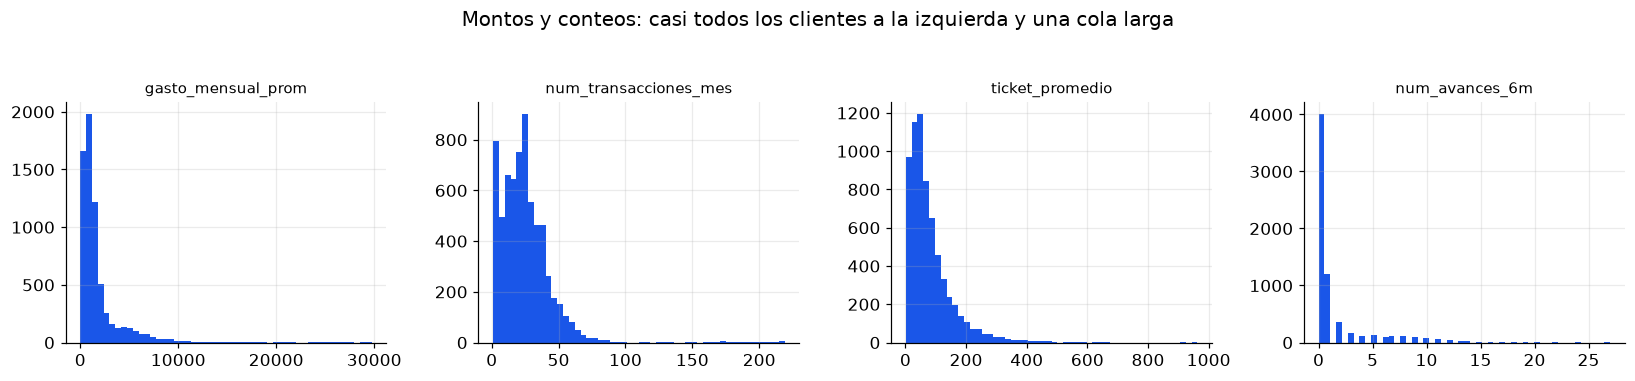

In [4]:
# ── DEMOSTRACIÓN A.0 ──────────────────────────────────────────────────
print(seg[VARS].describe(percentiles=[0.5, 0.9]).T[["mean", "std", "min", "50%", "90%", "max"]].round(2).to_string())

fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
for ax, var in zip(axes, LOG):
    ax.hist(seg[var], bins=50, color=BLUE)
    ax.set_title(var, fontsize=10)
plt.suptitle("Montos y conteos: casi todos los clientes a la izquierda y una cola larga", y=1.04)
plt.tight_layout(); plt.show()

Dos problemas:

1. **Escalas muy distintas.** El gasto tiene una desviación estándar de **S/ 2 638**; los porcentajes, de 0.1 a 0.3. En la
   distancia euclidiana, el gasto lo decide todo.
2. **Colas largas.** Unos pocos clientes gastan S/ 15 000 o más al mes. En una distancia al cuadrado, esos pocos tiran de
   los centros de los grupos.

La receta estándar: **logaritmo** a los montos y conteos (`np.log1p`, que es $\log(1 + x)$ y aguanta los ceros), y después
**estandarizar** todas las variables (media 0, desviación 1) con `StandardScaler`.

### Ejercicio A.1 — La matriz para agrupar

1. `Z`: una copia de `seg[VARS]` con `np.log1p` aplicado a las columnas de `LOG`.
2. `escalador`: un `StandardScaler()` ajustado sobre `Z`.
3. `Zs`: la matriz escalada (`escalador.transform(Z)`).

In [5]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
Z = seg[VARS].copy()
Z[LOG] = np.log1p(Z[LOG])
escalador = StandardScaler().fit(Z)
Zs = escalador.transform(Z)
print(f"Zs: {Zs.shape[0]} filas × {Zs.shape[1]} columnas")
print("medias:", Zs.mean(axis=0).round(3))
print("desv. estándar:", Zs.std(axis=0).round(3))

Zs: 6685 filas × 12 columnas
medias: [-0. -0.  0.  0.  0. -0.  0. -0.  0.  0.  0. -0.]
desv. estándar: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [6]:
# ── VERIFICACIÓN A.1 ──────────────────────────────────────────────────
r = [check_bool("Zs tiene 6 685 filas y 12 columnas", Zs is not None and Zs.shape == (6685, 12)),
     check("media de todas las columnas", None if Zs is None else np.abs(Zs.mean(axis=0)).max(), 0.0, tol=1e-6),
     check("desviación de todas las columnas", None if Zs is None else Zs.std(axis=0).mean(), 1.0, tol=1e-6),
     check("logaritmo del gasto, sin escalar, en el primer cliente", None if Z is None else Z["gasto_mensual_prom"].iloc[0], 6.6093, tol=0.001)]
print()
print("A.1 OK" if all(r) else "Revisa A.1")

[OK] Zs tiene 6 685 filas y 12 columnas
[OK] media de todas las columnas
     tu resultado: 0.0000   |   esperado: 0.0000
[OK] desviación de todas las columnas
     tu resultado: 1.0000   |   esperado: 1.0000
[OK] logaritmo del gasto, sin escalar, en el primer cliente
     tu resultado: 6.6093   |   esperado: 6.6093

A.1 OK


### Demostración A.2 — ¿Qué pasa si no escalas?

Corremos K-Means con 6 grupos **sobre los datos crudos** y miramos dos cosas: cuánta de la varianza total viene de cada
variable, y el tamaño de los grupos.

In [7]:
# ── DEMOSTRACIÓN A.2 ──────────────────────────────────────────────────
varianza = seg[VARS].var()
print("Participación de cada variable en la varianza total (datos crudos):")
print((varianza / varianza.sum()).sort_values(ascending=False).head(4).map("{:.2%}".format).to_string())

crudo = KMeans(6, n_init=10, random_state=SEED).fit(seg[VARS])
tabla = pd.DataFrame({"clientes": pd.Series(crudo.labels_).value_counts(),
                      "gasto medio (S/)": seg.groupby(crudo.labels_)["gasto_mensual_prom"].mean().round(0)}).sort_values("gasto medio (S/)")
print("\nK-Means con 6 grupos SIN escalar:")
print(tabla.to_string())

Participación de cada variable en la varianza total (datos crudos):
gasto_mensual_prom       99.91%
ticket_promedio           0.08%
num_transacciones_mes     0.01%
num_avances_6m            0.00%

K-Means con 6 grupos SIN escalar:
   clientes  gasto medio (S/)
0      3738             632.0
2      1948            1827.0
5       607            4521.0
4       297            7591.0
1        62           12931.0
3        33           24441.0


**El gasto explica el 99.9 % de la varianza** de los datos crudos (y el ticket casi todo el resto). Sin escalar, K-Means no
encuentra tipos de cliente: corta a la cartera **en rebanadas de gasto**, del grupo que gasta poco al que gasta mucho. Los
porcentajes, el pago, la app y los avances no participan.

> **Regla:** en clustering con distancias, **siempre** se escala. Y se decide antes qué variables entran, porque cada una
> que entra «vota» en la distancia. Agregar tres variables de gasto parecidas es darle tres votos al gasto.

---
# Bloque B · K-Means  ·  20 min

K-Means busca $k$ **centros** y asigna cada cliente al centro más cercano. El algoritmo (de Lloyd) repite dos pasos:

1. **Asignar:** cada cliente va al centro más cercano.
2. **Mover:** cada centro se mueve al **promedio** de sus clientes.

Hasta que ningún cliente cambia de grupo. Lo que minimiza es la **inercia**: la suma de las distancias al cuadrado de cada
cliente a su centro. Detalles que importan en `sklearn`:

- `n_clusters=k` hay que **dárselo**. K-Means no decide cuántos grupos hay.
- Los centros iniciales se eligen con **k-means++** (separados entre sí), y `n_init=10` corre todo 10 veces y se queda con la
  menor inercia, porque el resultado depende del punto de partida.
- `random_state` fija los sorteos para que todos obtengamos lo mismo.

### Ejercicio B.1 — Inercia y silueta para k de 2 a 10

La inercia **siempre** baja al agregar grupos (con $k = n$ es cero), así que sola no sirve para elegir. La complementamos con
la **silueta**: para cada cliente, $a$ es la distancia media a los de su grupo y $b$ la distancia media al grupo vecino más
cercano.

$$s = \frac{b - a}{\max(a, b)} \in [-1, 1]$$

Cerca de 1: el cliente está bien metido en su grupo. Cerca de 0: está en la frontera. Negativo: probablemente en el grupo
equivocado. La silueta del modelo es el promedio.

Para cada `k` de 2 a 10, ajusta `KMeans(k, n_init=10, random_state=SEED)` sobre `Zs` y guarda en `resultados` una fila con
`k`, `inercia` (`.inertia_`) y `silueta` (`silhouette_score(Zs, modelo.labels_)`).

In [8]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
filas = []
for k in range(2, 20):
    modelo = KMeans(k, n_init=10, random_state=SEED).fit(Zs)
    filas.append({"k": k, "inercia": modelo.inertia_, "silueta": silhouette_score(Zs, modelo.labels_)})
resultados = pd.DataFrame(filas).set_index("k")
print(resultados.round(4).to_string())

       inercia  silueta
k                      
2   61624.2793   0.2691
3   47356.3142   0.3217
4   36845.9334   0.3779
5   29957.4422   0.3228
6   25944.7317   0.3345
7   24838.5598   0.2754
8   23383.6240   0.2837
9   22598.6160   0.2530
10  21826.7039   0.2417
11  21166.6614   0.2079
12  20625.3993   0.1971
13  19912.7094   0.1783
14  19324.3333   0.1629
15  19060.9931   0.1563
16  18586.8373   0.1540
17  18214.6068   0.1567
18  17949.8455   0.1496
19  17654.1801   0.1427


[OK] silueta con k = 4
     tu resultado: 0.3779   |   esperado: 0.3779
[OK] silueta con k = 6
     tu resultado: 0.3345   |   esperado: 0.3345
[OK] inercia con k = 6
     tu resultado: 25944.7317   |   esperado: 25945.0000
[OK] la inercia baja siempre

B.1 OK


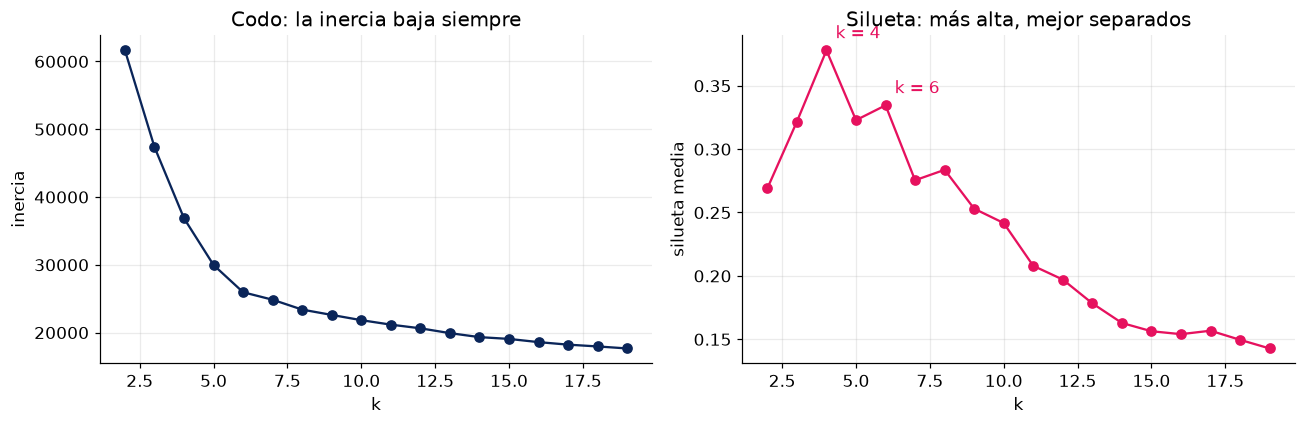

In [9]:
# ── VERIFICACIÓN B.1 ──────────────────────────────────────────────────
def res(k, col):
    return None if resultados is None or k not in resultados.index else resultados.loc[k, col]
r = [check("silueta con k = 4", res(4, "silueta"), 0.3779, tol=0.01),
     check("silueta con k = 6", res(6, "silueta"), 0.3345, tol=0.01),
     check("inercia con k = 6", res(6, "inercia"), 25945, tol=300),
     check_bool("la inercia baja siempre", resultados is not None and bool((resultados["inercia"].diff().dropna() < 0).all()))]
print()
print("B.1 OK" if all(r) else "Revisa B.1")
if resultados is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(resultados.index, resultados["inercia"], "o-", color=NAVY)
    axes[0].set_title("Codo: la inercia baja siempre"); axes[0].set_xlabel("k"); axes[0].set_ylabel("inercia")
    axes[1].plot(resultados.index, resultados["silueta"], "o-", color=MAG)
    for k in [4, 6]:
        axes[1].annotate(f"k = {k}", (k, resultados.loc[k, "silueta"]), textcoords="offset points", xytext=(6, 8), color=MAG)
    axes[1].set_title("Silueta: más alta, mejor separados"); axes[1].set_xlabel("k"); axes[1].set_ylabel("silueta media")
    plt.tight_layout(); plt.show()

Lo que dicen los dos gráficos:

- **El codo no es nítido.** La inercia baja fuerte hasta 4 y sigue bajando bien hasta 6. Después se aplana. Un codo «de
  libro» casi nunca aparece en datos reales.
- **La silueta prefiere k = 4** (0.378), y k = 6 queda segunda en el grupo de arriba (0.335).

¿Nos quedamos con 4? **Las métricas no deciden solas.** Antes de elegir, hay que mirar qué separa cada opción. Eso es el
Bloque C. Las siluetas de 0.3 a 0.4 son normales en datos de clientes: los segmentos existen, pero se tocan en los bordes.

---
# Bloque C · Perfilar, nombrar y cruzar con el negocio  ·  15 min

### Ejercicio C.1 — K-Means con 6 grupos y su perfil

1. `km6`: `KMeans(6, n_init=10, random_state=SEED)` ajustado sobre `Zs`.
2. Agrega la columna `cluster` a `seg` con las etiquetas.
3. `perfil`: el **promedio de cada variable de `VARS` y `PERFIL`** por cluster (en las unidades originales, no en `Zs`), con
   una columna más, `clientes`, con el tamaño de cada grupo.

In [10]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
km6 = KMeans(6, n_init=10, random_state=SEED).fit(Zs)
seg["cluster"] = km6.labels_
perfil = seg.groupby("cluster")[VARS + PERFIL].mean()
perfil["clientes"] = seg.groupby("cluster").size()
print(perfil.round(2).T.to_string())

cluster                      0         1        2        3        4        5
gasto_mensual_prom     1369.32   5629.42    50.63   578.56  1690.83  1610.09
num_transacciones_mes    24.95     34.88     1.61     8.39    49.43    19.98
ticket_promedio          62.69    179.69    40.33    87.90    23.73    94.72
pct_supermercado          0.44      0.14     0.32     0.39     0.09     0.36
pct_restaurantes          0.14      0.21     0.12     0.13     0.19     0.21
pct_viajes                0.03      0.28     0.03     0.03     0.02     0.03
pct_online                0.15      0.23     0.13     0.07     0.55     0.15
utilizacion_prom          0.39      0.37     0.17     0.47     0.42     0.76
pct_pago_saldo            0.59      0.94     0.79     0.14     0.49     0.14
num_avances_6m            0.30      0.09     0.12     7.38     1.00     1.04
pct_operaciones_app       0.38      0.61     0.18     0.13     0.92     0.35
meses_sin_uso_6m          0.19      0.16     4.98     0.17     0.17     0.15

In [11]:
# ── VERIFICACIÓN C.1 ──────────────────────────────────────────────────
r = [check_bool("perfil tiene 6 grupos", perfil is not None and len(perfil) == 6),
     check("el grupo más grande", None if perfil is None else perfil["clientes"].max(), 2133, tol=40),
     check("el grupo más chico", None if perfil is None else perfil["clientes"].min(), 531, tol=20),
     check("el mayor % de viajes de un grupo", None if perfil is None else perfil["pct_viajes"].max(), 0.276, tol=0.01)]
print()
print("C.1 OK" if all(r) else "Revisa C.1")

[OK] perfil tiene 6 grupos
[OK] el grupo más grande
     tu resultado: 2133.0000   |   esperado: 2133.0000
[OK] el grupo más chico
     tu resultado: 531.0000   |   esperado: 531.0000
[OK] el mayor % de viajes de un grupo
     tu resultado: 0.2765   |   esperado: 0.2760

C.1 OK


### Demostración C.2 — El perfil en un mapa de calor

Una tabla de promedios con 12 variables y 6 grupos es difícil de leer. El truco: mostrar cada promedio como **cuántas
desviaciones estándar está sobre o bajo la media de la cartera**. Rojo, el grupo destaca por arriba; azul, por abajo.

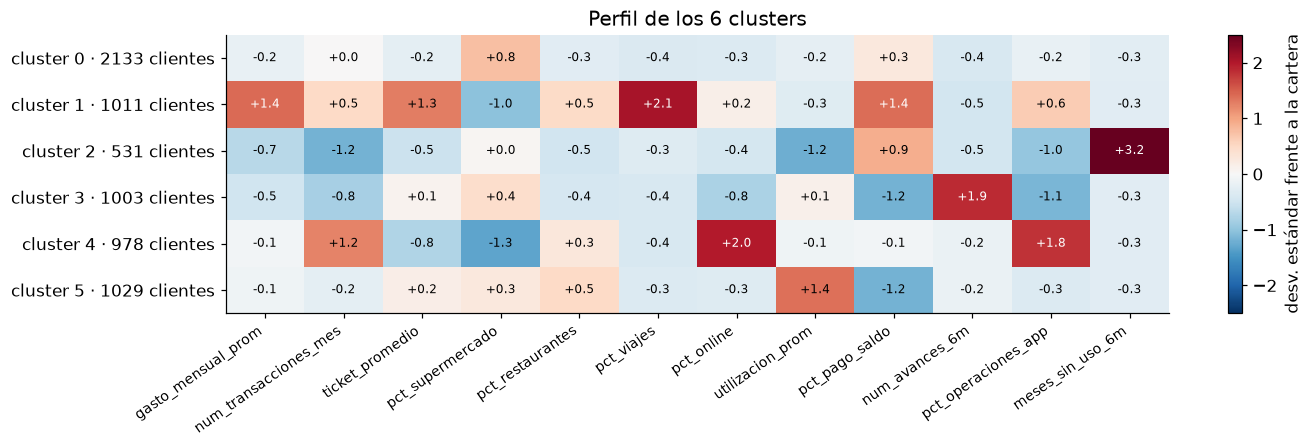

In [12]:
# ── DEMOSTRACIÓN C.2 ──────────────────────────────────────────────────
if perfil is not None:
    z_perfil = (perfil[VARS] - seg[VARS].mean()) / seg[VARS].std()
    fig, ax = plt.subplots(figsize=(13, 4.2))
    im = ax.imshow(z_perfil.values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
    ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=35, ha="right", fontsize=9)
    ax.set_yticks(range(len(perfil))); ax.set_yticklabels([f"cluster {c} · {n} clientes" for c, n in perfil["clientes"].items()])
    for (f, c), v in np.ndenumerate(z_perfil.values):
        ax.text(c, f, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1.4 else "black")
    ax.grid(False); plt.colorbar(im, label="desv. estándar frente a la cartera")
    ax.set_title("Perfil de los 6 clusters")
    plt.tight_layout(); plt.show()

### Ejercicio C.3 — Ponles nombre

Los números de cluster (0, 1, 2…) no significan nada, y **pueden cambiar** si cambia la versión de `sklearn` o la semilla.
Por eso el nombre se pone con **reglas sobre el perfil**, no con el número. Mirando el mapa de calor, completa `nombrar`:

| Nombre | Regla |
|---|---|
| Dormido | el de más `meses_sin_uso_6m` |
| Premium viajero | el de más `pct_viajes` |
| Usuario de efectivo | el de más `num_avances_6m` |
| Digital joven | el de más `pct_operaciones_app` |
| Revolvente | de los que quedan, el de más `utilizacion_prom` |
| Cotidiano | el que queda |

La función devuelve un diccionario `{número de cluster: nombre}`. Después crea la columna `segmento` en `seg`.

In [13]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
def nombrar(perfil):
    nombres, libres = {}, list(perfil.index)
    for nombre, var in [("Dormido", "meses_sin_uso_6m"), ("Premium viajero", "pct_viajes"),
                        ("Usuario de efectivo", "num_avances_6m"), ("Digital joven", "pct_operaciones_app"),
                        ("Revolvente", "utilizacion_prom")]:
        c = perfil.loc[libres, var].idxmax()
        nombres[c] = nombre
        libres.remove(c)
    nombres[libres[0]] = "Cotidiano"
    return nombres

nombres = nombrar(perfil)
seg["segmento"] = seg["cluster"].map(nombres)
print(seg["segmento"].value_counts().to_string())

segmento
Cotidiano              2133
Revolvente             1029
Premium viajero        1011
Usuario de efectivo    1003
Digital joven           978
Dormido                 531


In [14]:
# ── VERIFICACIÓN C.3 ──────────────────────────────────────────────────
tam = seg["segmento"].value_counts() if "segmento" in seg else None
def t(nombre):
    return None if tam is None or nombre not in tam.index else tam[nombre]
r = [check_bool("hay 6 nombres distintos", tam is not None and len(tam) == 6, "¿completaste las tres reglas que faltan y el 'Cotidiano'?"),
     check("clientes en Cotidiano", t("Cotidiano"), 2133, tol=40),
     check("clientes en Revolvente", t("Revolvente"), 1029, tol=40),
     check("clientes en Dormido", t("Dormido"), 531, tol=20)]
print()
print("C.3 OK" if all(r) else "Revisa C.3")

[OK] hay 6 nombres distintos
[OK] clientes en Cotidiano
     tu resultado: 2133.0000   |   esperado: 2133.0000
[OK] clientes en Revolvente
     tu resultado: 1029.0000   |   esperado: 1029.0000
[OK] clientes en Dormido
     tu resultado: 531.0000   |   esperado: 531.0000

C.3 OK


### Ejercicio C.4 — ¿Los segmentos dicen algo del riesgo?

El clustering **no vio el default**. Si los segmentos tienen tasas de default distintas, encontramos algo que el negocio puede
usar. De la cartera de la Clase 9, toma la **última foto de 2026** de cada cliente (`periodo` desde `2026-01`, la fila de
mayor `periodo` por cliente) con su `default_3m`, únela a `seg` por `id_cliente` y arma `riesgo_seg`: clientes y **tasa de
default** por segmento, ordenada de mayor a menor tasa.

In [15]:
# ── SOLUCIÓN ─────────────────────────────────────────────────────────────
ultima = (cartera[cartera["periodo"] >= "2026-01"].sort_values("periodo")
          .groupby(ID).tail(1)[[ID, "default_3m"]])
base_riesgo = seg.merge(ultima, on=ID, how="left")
riesgo_seg = (base_riesgo.groupby("segmento").agg(clientes=(ID, "size"), tasa_default=("default_3m", "mean"))
              .sort_values("tasa_default", ascending=False))
tasa_cartera = base_riesgo["default_3m"].mean()
riesgo_seg["lift"] = riesgo_seg["tasa_default"] / tasa_cartera
print(riesgo_seg.round(3).to_string())
print(f"\nTasa de toda la cartera: {tasa_cartera:.2%}")

                     clientes  tasa_default   lift
segmento                                          
Revolvente               1029         0.217  2.395
Usuario de efectivo      1003         0.153  1.686
Digital joven             978         0.075  0.825
Cotidiano                2133         0.049  0.539
Dormido                   531         0.040  0.437
Premium viajero          1011         0.031  0.339

Tasa de toda la cartera: 9.05%


[OK] tasa de default de toda la base
     tu resultado: 0.0905   |   esperado: 0.0905
[OK] tasa de default de Revolvente
     tu resultado: 0.2167   |   esperado: 0.2170
[OK] tasa de default de Premium viajero
     tu resultado: 0.0307   |   esperado: 0.0310
[OK] el más riesgoso es Revolvente

C.4 OK


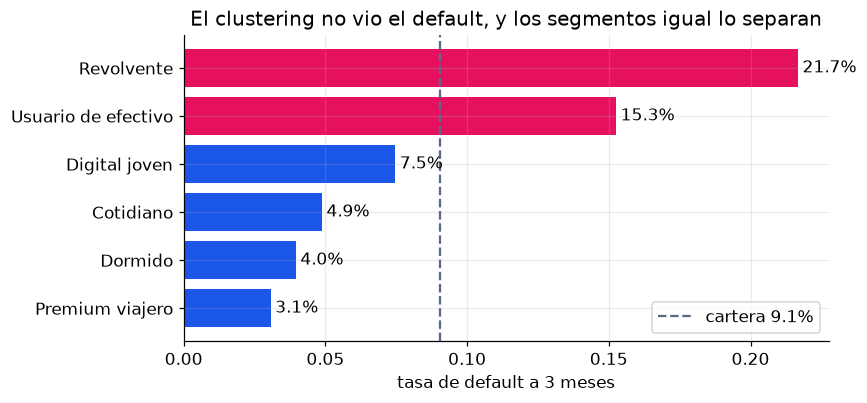

In [16]:
# ── VERIFICACIÓN C.4 ──────────────────────────────────────────────────
def tasa(nombre):
    return None if riesgo_seg is None or nombre not in riesgo_seg.index else riesgo_seg.loc[nombre, "tasa_default"]
r = [check("tasa de default de toda la base", tasa_cartera, 0.0905, tol=0.002),
     check("tasa de default de Revolvente", tasa("Revolvente"), 0.217, tol=0.015),
     check("tasa de default de Premium viajero", tasa("Premium viajero"), 0.031, tol=0.01),
     check_bool("el más riesgoso es Revolvente", riesgo_seg is not None and riesgo_seg.index[0] == "Revolvente")]
print()
print("C.4 OK" if all(r) else "Revisa C.4")
if riesgo_seg is not None:
    s = riesgo_seg["tasa_default"].sort_values()
    plt.figure(figsize=(8, 3.8))
    barras = plt.barh(s.index, s.values, color=[MAG if v > tasa_cartera else BLUE for v in s.values])
    plt.bar_label(barras, labels=[f"{v:.1%}" for v in s.values], padding=3)
    plt.axvline(tasa_cartera, color=GRAY, ls="--", label=f"cartera {tasa_cartera:.1%}")
    plt.xlabel("tasa de default a 3 meses"); plt.title("El clustering no vio el default, y los segmentos igual lo separan"); plt.legend()
    plt.tight_layout(); plt.show()

**Revolvente** tiene una tasa de **21.7 %**, 2.4 veces la cartera, y **Usuario de efectivo**, 15.3 %. En el otro extremo,
**Premium viajero** cae al 3.1 %. El algoritmo nunca vio el default: separó a los clientes por **cómo usan la tarjeta**, y esa
forma de uso resulta estar ligada al riesgo. Eso es lo que convierte un clustering en una herramienta de negocio: cada
segmento pide una acción distinta (campañas de viaje para unos, alertas tempranas de cobranza para otros).

> **Cuidado:** esto **no** reemplaza al score de la Clase 9. El score se entrenó para predecir el default y lo hace mejor.
> El segmento responde otra pregunta: **quién es** el cliente, para decidir **cómo hablarle**.

### Demostración C.5 — ¿Y si nos quedábamos con k = 4?

In [17]:
# ── DEMOSTRACIÓN C.5 ──────────────────────────────────────────────────
if riesgo_seg is not None:
    km4 = KMeans(4, n_init=10, random_state=SEED).fit(Zs)
    cruce = pd.crosstab(seg["segmento"], km4.labels_)
    print("Segmentos de k = 6 (filas) dentro de los grupos de k = 4 (columnas):\n")
    print(cruce.to_string())
    grande = cruce.sum().idxmax()
    dentro = base_riesgo[km4.labels_ == grande]
    print(f"\nEl grupo {grande} de k = 4 junta {len(dentro)} clientes con una tasa de default de {dentro['default_3m'].mean():.1%}.")
    print("Por dentro:", dentro.groupby("segmento")["default_3m"].mean().round(3).to_dict())

Segmentos de k = 6 (filas) dentro de los grupos de k = 4 (columnas):

col_0                   0     1    2    3
segmento                                 
Cotidiano               7  2120    6    0
Digital joven           0     0  978    0
Dormido                 0     0    0  531
Premium viajero      1011     0    0    0
Revolvente              0  1029    0    0
Usuario de efectivo     0  1003    0    0

El grupo 1 de k = 4 junta 4152 clientes con una tasa de default de 11.6%.
Por dentro: {'Cotidiano': 0.049, 'Revolvente': 0.217, 'Usuario de efectivo': 0.153}


Con k = 4, **Cotidiano, Revolvente y Usuario de efectivo quedan en un solo grupo** de más de 4 000 clientes, con una tasa
cercana al 12 %. Adentro conviven tasas de 5 % y de 22 %. La silueta prefería k = 4 porque esos tres segmentos están cerca
entre sí (se parecen en gasto y en mezcla de compras), pero **para el negocio son clientes muy distintos**.

> **Cómo se elige k en la práctica:** las métricas proponen un rango (aquí, de 4 a 6), y la decisión final la toman la
> **interpretabilidad** de los grupos y la **utilidad** para la acción que se quiere tomar.

### Demostración C.6 — Los clusters en dos dimensiones, y un aviso sobre los extremos

Con **PCA** proyectamos las 12 variables escaladas a 2 dimensiones solo para **mirar** (no para agrupar).

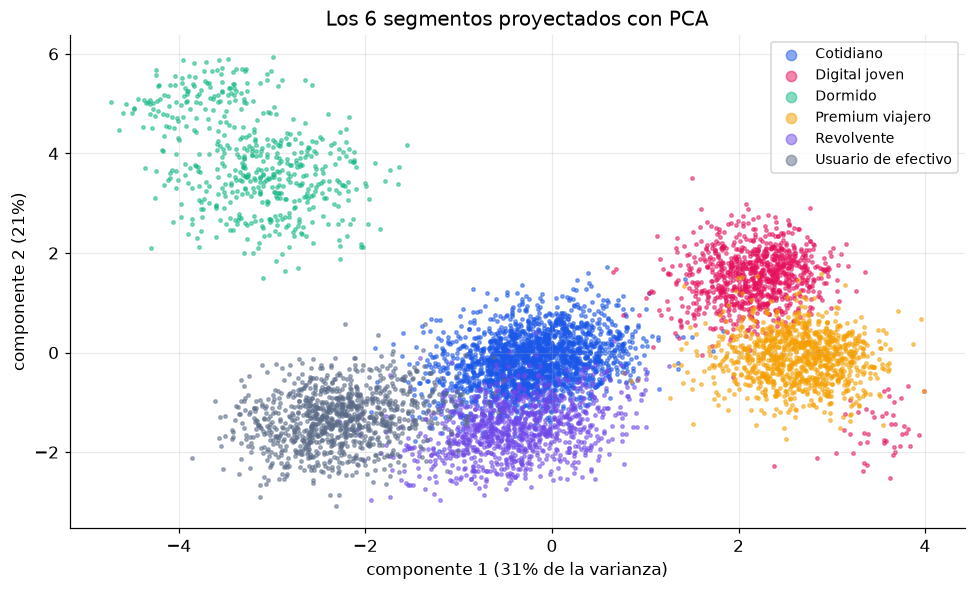

Gasto mensual por segmento: promedio, mediana y máximo (S/)

                       mean  median    max
segmento                                  
Premium viajero      5629.0  5186.0  17296
Digital joven        1691.0   663.0  29766
Revolvente           1610.0  1494.0   6754
Cotidiano            1369.0  1265.0   5671
Usuario de efectivo   579.0   528.0   2027
Dormido                51.0    44.0    242


In [18]:
# ── DEMOSTRACIÓN C.6 ──────────────────────────────────────────────────
if "segmento" in seg:
    pca = PCA(2, random_state=SEED).fit(Zs)
    P = pca.transform(Zs)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for color, (nombre, idx) in zip(COLORES, seg.groupby("segmento").groups.items()):
        ax.scatter(P[idx, 0], P[idx, 1], s=5, alpha=0.5, color=color, label=nombre)
    ax.set_xlabel(f"componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)")
    ax.set_ylabel(f"componente 2 ({pca.explained_variance_ratio_[1]:.0%})")
    ax.set_title("Los 6 segmentos proyectados con PCA"); ax.legend(markerscale=3, fontsize=9)
    plt.tight_layout(); plt.show()

    gasto = seg.groupby("segmento")["gasto_mensual_prom"].agg(["mean", "median", "max"]).round(0)
    print("Gasto mensual por segmento: promedio, mediana y máximo (S/)\n")
    print(gasto.sort_values("mean", ascending=False).to_string())

Dos lecturas:

- En dos dimensiones los segmentos **se tocan** y algunos se enciman: el PCA solo conserva parte de la varianza. Que se
  enciman en el dibujo no significa que se enciman en las 12 dimensiones.
- En **Digital joven**, el gasto **promedio** es mucho mayor que la mediana, y el máximo pasa de S/ 25 000. Hay un puñado
  de clientes con patrones de gasto extremos que K-Means **tuvo que meter en algún grupo**: K-Means asigna a todos, no tiene
  la opción de decir «este cliente no se parece a nadie». Para eso están los algoritmos de densidad de la parte 2.

---
# Cierre de la segunda hora

### Los números del día

| | |
|---|---|
| Clientes | 6 685, con 12 variables de comportamiento |
| Varianza del gasto sin escalar | 99.9 % del total |
| Silueta | 0.378 con k = 4 · 0.335 con k = 6 |
| Segmentos (k = 6) | Cotidiano, Revolvente, Digital joven, Premium viajero, Usuario de efectivo, Dormido |
| Tasa de default | de 3.1 % (Premium viajero) a 21.7 % (Revolvente); cartera 9.1 % |

### Checklist de salida

- [ ] Explico qué cambia cuando no hay target y qué preguntas de negocio responde el clustering.
- [ ] Sé por qué hay que aplicar logaritmo a montos sesgados y **escalar** antes de usar distancias.
- [ ] Explico los dos pasos de K-Means, la inercia, k-means++ y para qué sirve `n_init`.
- [ ] Calculo e interpreto el codo y la **silueta**, y sé que no deciden solos el número de grupos.
- [ ] Perfilo los clusters en las unidades originales, los nombro con reglas y los cruzo con una variable de negocio.

### Preguntas tipo examen

**1.** Un analista corre K-Means sobre gasto (en soles), edad y % de pago, sin escalar. ¿Qué va a pasar?

> **Respuesta.** El gasto, con la varianza más grande, domina la distancia: los grupos van a ser rebanadas de gasto y las
> otras variables casi no van a influir. Hay que escalar (y, si el gasto es muy sesgado, aplicarle logaritmo antes).

**2.** La inercia con k = 10 es menor que con k = 6. ¿Es mejor el modelo de 10 grupos?

> **Respuesta.** No necesariamente. La inercia **siempre** baja al agregar grupos (con un grupo por cliente es cero). Hay
> que mirar dónde deja de bajar mucho (codo), la silueta y, sobre todo, si los grupos se pueden interpretar y usar.

**3.** Un cliente tiene silueta de −0.2. ¿Qué significa?

> **Respuesta.** Que está, en promedio, más cerca de los clientes del grupo vecino que de los de su propio grupo:
> probablemente quedó en el grupo equivocado, o está en la frontera entre dos segmentos.

**4.** ¿Por qué corremos K-Means con `n_init=10`?

> **Respuesta.** Porque el resultado depende de los centros iniciales y puede quedarse en un mínimo local. Con 10 arranques
> distintos se queda con el de menor inercia.

**5.** La silueta prefiere k = 4, pero el equipo elige k = 6. ¿Se justifica?

> **Respuesta.** Sí: con k = 4, un grupo junta segmentos con tasas de default de 5 % y 22 %, que requieren acciones
> distintas. Las métricas proponen un rango; la interpretabilidad y la utilidad deciden.

### Lo que sigue

**Clustering · Parte 2.** Los algoritmos que no son K-Means: **jerárquico** (y el dendrograma), **DBSCAN y HDBSCAN** (que sí
pueden decir «este cliente no se parece a nadie»), **mezclas gaussianas** (pertenencia con probabilidad) y cómo **comparar**
algoritmos entre sí.